In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import make_blobs, fetch_openml
from sklearn.metrics import adjusted_rand_score
from joblib import Parallel, delayed

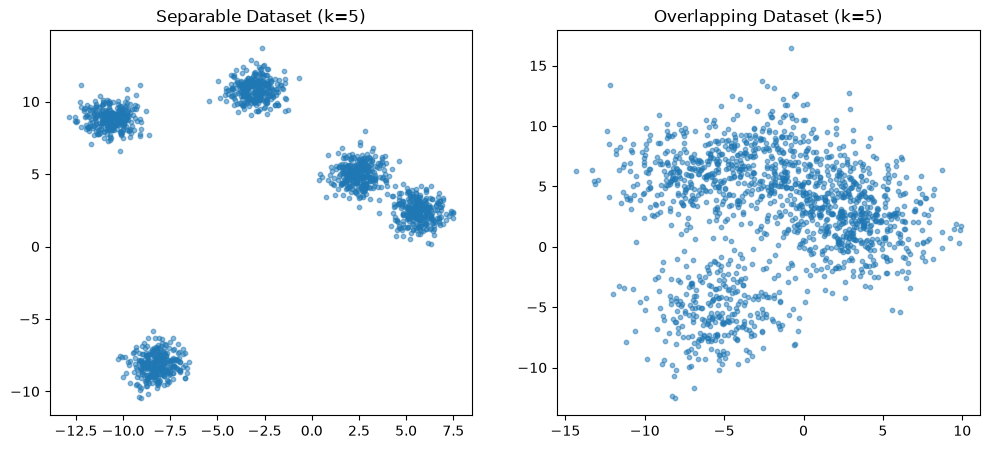

In [2]:
def generate_synthetic_separable(n_samples=1500, k=5, seed=42):
    return make_blobs(n_samples=n_samples, n_features=2, centers=k, cluster_std=0.75, center_box=(-12.0, 12.0), random_state=seed, return_centers=False)

def generate_synthetic_overlapping(n_samples=1500, k=5, seed=42):
    return make_blobs(n_samples=n_samples, n_features=2, centers=k, cluster_std=2.4, center_box=(-8.0, 8.0), random_state=seed, return_centers=False)

def generate_synthetic_high_dim(n_samples=1500, k=5, d=100, seed=42):
    return make_blobs(n_samples=n_samples, n_features=d, centers=k, cluster_std=1.5, random_state=seed, return_centers=False)

def load_mnist_subset(n_samples=3000, seed=42):
    mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff")
    X, y = mnist.data.astype(np.float64), mnist.target.astype(int)
    rng = np.random.RandomState(seed)
    indices = rng.choice(len(X), size=n_samples, replace=False)
    return X[indices] / 255.0, y[indices]

X_sep, _ = generate_synthetic_separable()
X_ovl, _ = generate_synthetic_overlapping()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.scatter(X_sep[:, 0], X_sep[:, 1], alpha=0.5, s=10)
ax1.set_title("Separable Dataset (k=5)")
ax2.scatter(X_ovl[:, 0], X_ovl[:, 1], alpha=0.5, s=10)
ax2.set_title("Overlapping Dataset (k=5)")
plt.show()

In [3]:
import pandas as pd

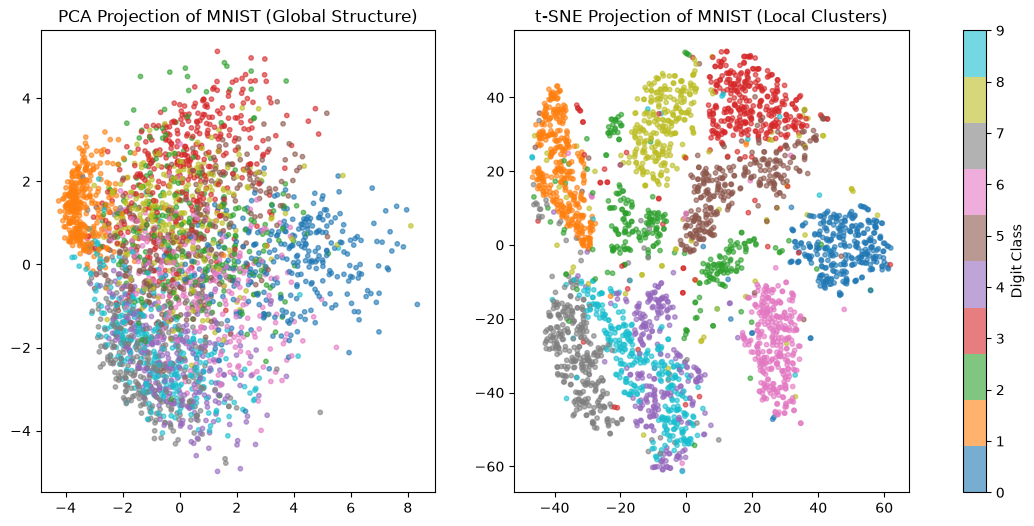

In [4]:
import numpy as np
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Call the previously defined function instead of fetching from scratch
X_mnist, y_mnist = load_mnist_subset(n_samples=3000, seed=42)

# 2. Run Dimensionality Reduction
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_mnist)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_mnist)

# 3. Plot with Matplotlib
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y_mnist, cmap='tab10', alpha=0.6, s=10)
ax1.set_title("PCA Projection of MNIST (Global Structure)")

scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_mnist, cmap='tab10', alpha=0.6, s=10)
ax2.set_title("t-SNE Projection of MNIST (Local Clusters)")

fig.colorbar(scatter2, ax=[ax1, ax2], label='Digit Class')
plt.show()

In [5]:
class ScratchKMeans:
    def __init__(self, n_clusters, init="kmeans++", max_iter=300, tol=1e-4, random_state=None):
        self.k = n_clusters
        self.init = init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    @staticmethod
    def _compute_sq_distances(X, centers, x_sq):
        c_sq = np.sum(centers**2, axis=1, keepdims=True).T
        dist_sq = np.dot(X, centers.T) * -2.0 + x_sq + c_sq
        np.maximum(dist_sq, 0.0, out=dist_sq)
        return dist_sq

    def _init_random(self, X, rng):
        indices = rng.choice(X.shape[0], size=self.k, replace=False)
        return X[indices].astype(np.float64, copy=True)

    def _init_kmeans_plus_plus(self, X, x_sq, rng):
        n_samples, n_features = X.shape
        centers = np.empty((self.k, n_features), dtype=np.float64)
        centers[0] = X[rng.randint(0, n_samples)]
        
        min_sq = x_sq.ravel() - 2.0 * np.dot(X, centers[0]) + float(np.sum(centers[0]**2))
        np.maximum(min_sq, 0.0, out=min_sq)

        for j in range(1, self.k):
            total_mass = float(np.sum(min_sq))
            if total_mass > 0.0:
                cum_mass = np.cumsum(min_sq)
                cutoff = rng.uniform(0.0, total_mass)
                next_idx = min(int(np.searchsorted(cum_mass, cutoff)), n_samples - 1)
            else:
                next_idx = rng.randint(0, n_samples)

            centers[j] = X[next_idx]
            new_sq = x_sq.ravel() - 2.0 * np.dot(X, centers[j]) + float(np.sum(centers[j]**2))
            np.maximum(new_sq, 0.0, out=new_sq)
            np.minimum(min_sq, new_sq, out=min_sq)
        return centers

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        rng = np.random.RandomState(self.random_state)
        x_sq = np.sum(X**2, axis=1, keepdims=True)

        self.centroids = self._init_random(X, rng) if self.init == "random" else self._init_kmeans_plus_plus(X, x_sq, rng)
        prev_centroids = self.centroids.copy()

        for iteration in range(1, self.max_iter + 1):
            dist_sq = self._compute_sq_distances(X, self.centroids, x_sq)
            labels = np.argmin(dist_sq, axis=1)

            new_centroids = np.empty_like(self.centroids)
            for c_idx in range(self.k):
                mask = labels == c_idx
                if np.any(mask):
                    new_centroids[c_idx] = np.mean(X[mask], axis=0)
                else:
                    new_centroids[c_idx] = X[np.argmax(np.min(dist_sq, axis=1))]

            shift = float(np.linalg.norm(new_centroids - prev_centroids))
            self.centroids = new_centroids
            prev_centroids = new_centroids.copy()
            self.n_iter_ = iteration
            if shift < self.tol:
                break

        final_dist_sq = self._compute_sq_distances(X, self.centroids, x_sq)
        self.labels_ = np.argmin(final_dist_sq, axis=1)
        self.inertia_ = float(np.sum(np.min(final_dist_sq, axis=1)))
        return self

In [6]:
def evaluate_stability(labels_list):
    n = len(labels_list)
    if n < 2: return 1.0
    scores = [adjusted_rand_score(labels_list[i], labels_list[j]) for i in range(n) for j in range(i + 1, n)]
    return np.mean(scores)

def _run_single_trial(seed, k, init, X):
    model = ScratchKMeans(n_clusters=k, init=init, random_state=seed).fit(X)
    return model.inertia_, model.n_iter_, model.labels_

def run_benchmark(X, k, n_trials=30):
    results = {}
    for init in ["random", "kmeans++"]:
        seeds = [2000 + i for i in range(n_trials)]
        out = Parallel(n_jobs=-1)(delayed(_run_single_trial)(s, k, init, X) for s in seeds)
        
        inertias = [item[0] for item in out]
        iterations = [item[1] for item in out]
        labels = [item[2] for item in out]
        
        results[init] = {
            "inertias": inertias,
            "iterations": iterations,
            "stability": evaluate_stability(labels)
        }
    return results

benchmarks = {
    "Separable": (X_sep, 5),
    "Overlapping": (X_ovl, 5)
}

experiment_results = {}
for name, (X, k) in benchmarks.items():
    print(f"Running {name} benchmark...")
    experiment_results[name] = run_benchmark(X, k, n_trials=20)
print("Experiments complete.")

Running Separable benchmark...
Running Overlapping benchmark...
Experiments complete.


In [10]:
# Experimental results

experiment_results

{'Separable': {'random': {'inertias': [4050.3885367474413,
    4042.225488442651,
    10865.520774400673,
    10865.520774400673,
    1636.708926587287,
    10863.441936925421,
    1636.708926587287,
    1636.708926587287,
    4031.407092711697,
    4065.6375136622864,
    1636.708926587287,
    1636.708926587287,
    4030.7143310246333,
    1636.708926587287,
    1636.708926587287,
    10865.520774400673,
    4051.4499400314585,
    1636.708926587287,
    4050.93983221086,
    1636.708926587287],
   'iterations': [12,
    9,
    19,
    12,
    6,
    8,
    5,
    4,
    6,
    4,
    5,
    3,
    14,
    4,
    6,
    18,
    15,
    8,
    7,
    3],
   'stability': np.float64(0.766330517694662)},
  'kmeans++': {'inertias': [1636.708926587287,
    1636.708926587287,
    1636.708926587287,
    1636.708926587287,
    1636.708926587287,
    4030.716969080965,
    1636.708926587287,
    4042.225488442651,
    1636.708926587287,
    1636.708926587287,
    1636.708926587287,
    1636.70

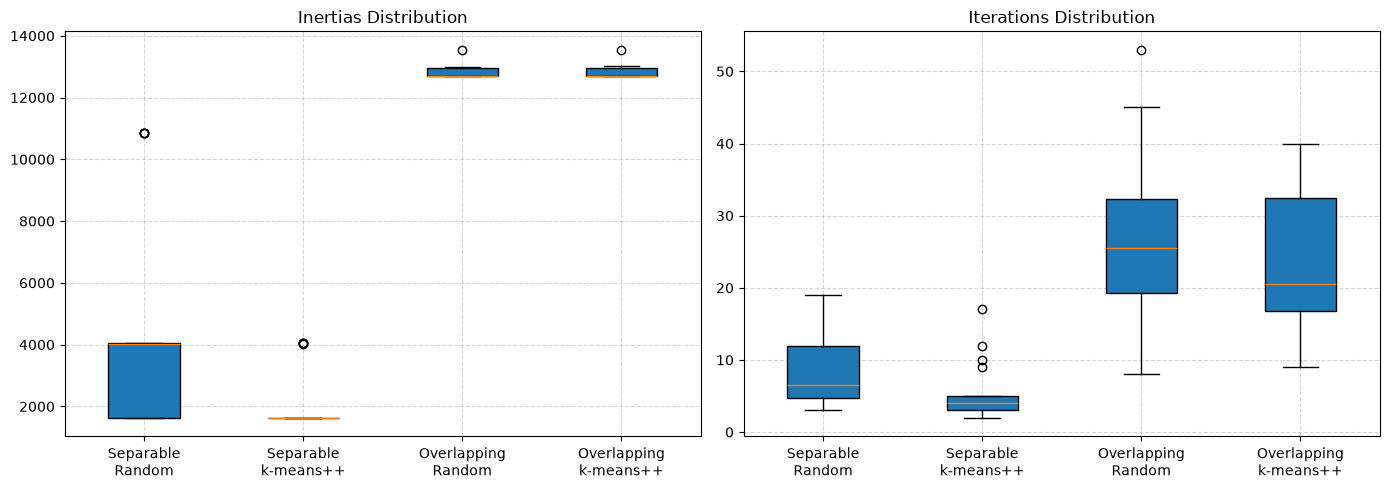

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = list(benchmarks.keys())

for idx, metric in enumerate(["inertias", "iterations"]):
    data = []
    labels = []
    for name in names:
        data.extend([experiment_results[name]["random"][metric], experiment_results[name]["kmeans++"][metric]])
        labels.extend([f"{name}\nRandom", f"{name}\nk-means++"])
    
    axes[idx].boxplot(data, patch_artist=True)
    axes[idx].set_xticklabels(labels)
    axes[idx].set_title(f"{metric.capitalize()} Distribution")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

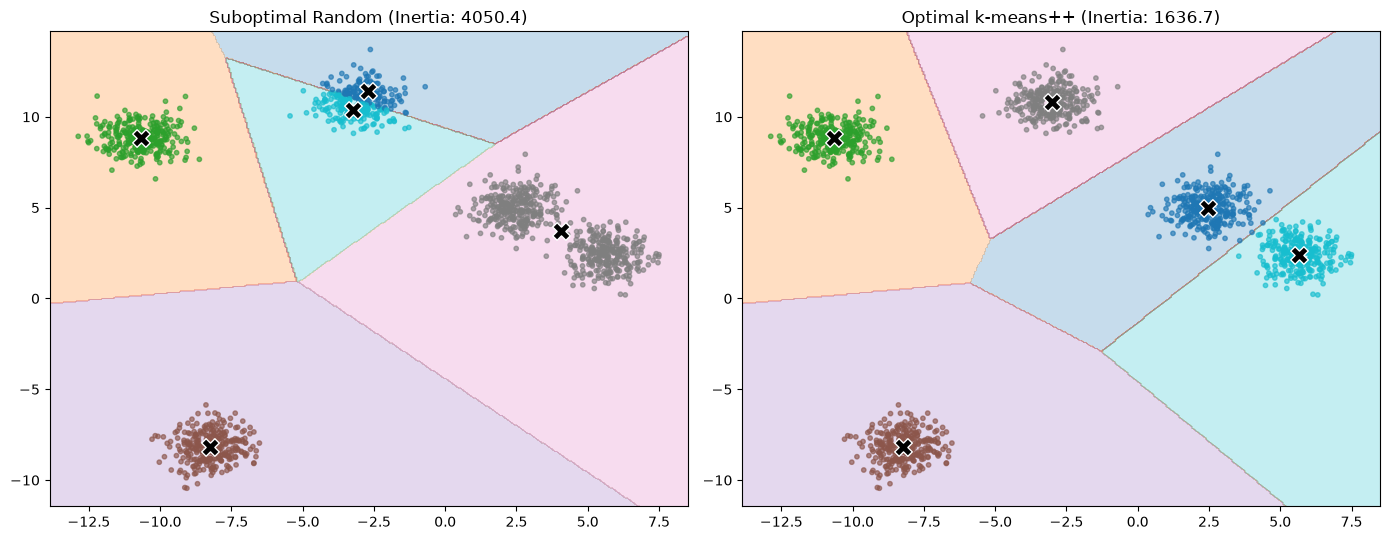

In [8]:
X = X_sep
bad_model = None
for seed in range(2000, 2200):
    model = ScratchKMeans(n_clusters=5, init="random", random_state=seed).fit(X)
    if 3900.0 < model.inertia_ < 4300.0:
        bad_model = model
        break

good_model = ScratchKMeans(n_clusters=5, init="kmeans++", random_state=2000).fit(X)

xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 400), 
                     np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 400))
grid = np.c_[xx.ravel(), yy.ravel()]
g_sq = np.sum(grid**2, axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, model, title in zip(axes, [bad_model, good_model], ["Suboptimal Random", "Optimal k-means++"]):
    dist_sq = model._compute_sq_distances(grid, model.centroids, g_sq)
    Z = np.argmin(dist_sq, axis=1).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="tab10")
    ax.scatter(X[:, 0], X[:, 1], c=model.labels_, s=10, cmap="tab10", alpha=0.65)
    ax.scatter(model.centroids[:, 0], model.centroids[:, 1], c="black", marker="X", s=160, edgecolors="white")
    ax.set_title(f"{title} (Inertia: {model.inertia_:.1f})")

plt.tight_layout()
plt.show()

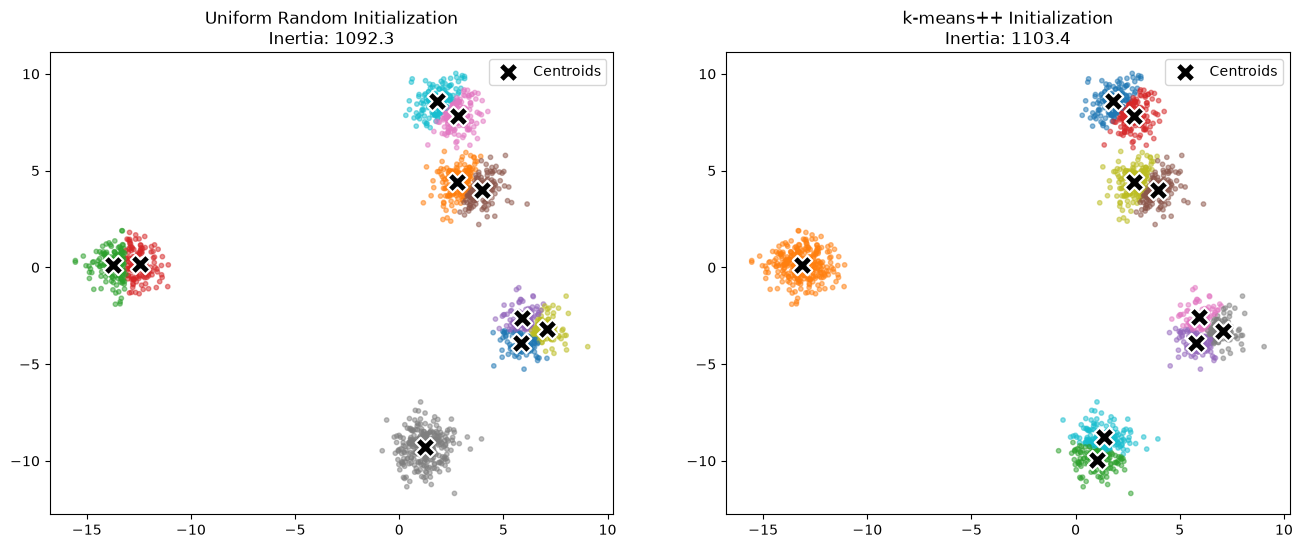

In [9]:
# For MNIST Dataset
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Fit both models on the raw 784D MNIST data
model_random = ScratchKMeans(n_clusters=10, init="random", random_state=42).fit(X)
model_kpp = ScratchKMeans(n_clusters=10, init="kmeans++", random_state=42).fit(X)

# 2. Fit PCA and project data and both sets of centroids to 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
centroids_random_pca = pca.transform(model_random.centroids)
centroids_kpp_pca = pca.transform(model_kpp.centroids)

# 3. Plot side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Random initialization plot
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=model_random.labels_, cmap='tab10', alpha=0.5, s=10)
ax1.scatter(
    centroids_random_pca[:, 0], centroids_random_pca[:, 1], 
    c="black", marker="X", s=200, edgecolors="white", linewidth=1.5, label="Centroids"
)
ax1.set_title(f"Uniform Random Initialization\nInertia: {model_random.inertia_:.1f}")
ax1.legend()

# k-means++ initialization plot
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=model_kpp.labels_, cmap='tab10', alpha=0.5, s=10)
ax2.scatter(
    centroids_kpp_pca[:, 0], centroids_kpp_pca[:, 1], 
    c="black", marker="X", s=200, edgecolors="white", linewidth=1.5, label="Centroids"
)
ax2.set_title(f"k-means++ Initialization\nInertia: {model_kpp.inertia_:.1f}")
ax2.legend()

plt.show()